In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

df = pd.read_csv(
    project_dir / "data/processed/fire_pm25_combined.csv",
    parse_dates=["date"]
)

df = df.sort_values(
    ["station_id", "date"]
).reset_index(drop=True)

print("Records:", len(df))
print("Stations:", df["station_id"].nunique())

display(df.head())


Records: 8548
Stations: 97


,State Code,County Code,Site Num,Parameter Code,POC,Latitude,Longitude,Datum,Parameter Name,Sample Duration,...,State Name,County Name,City Name,CBSA Name,Date of Last Change,method_priority,station_id,fire_count_50km,fire_count_100km,frp_sum_100km
0,6,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,24-HR BLK AVG,...,California,Butte,Chico,"Chico, CA",2026-02-23,2.0,06-007-0008,6,11,55.47
1,6,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,24-HR BLK AVG,...,California,Butte,Chico,"Chico, CA",2026-02-23,2.0,06-007-0008,4,5,30.24
2,6,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,24-HR BLK AVG,...,California,Butte,Chico,"Chico, CA",2026-02-23,2.0,06-007-0008,0,4,22.92
3,6,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,24-HR BLK AVG,...,California,Butte,Chico,"Chico, CA",2026-02-23,2.0,06-007-0008,4,4,17.04
4,6,7,8,88101,3,39.76168,-121.84047,NAD83,PM2.5 - Local Conditions,24-HR BLK AVG,...,California,Butte,Chico,"Chico, CA",2026-02-23,2.0,06-007-0008,3,3,27.69


In [2]:

# Preserve original values
df["pm25_original"] = df["pm25"]

# Negative PM2.5 is not physically meaningful
df.loc[df["pm25"] < 0, "pm25"] = np.nan

print("Missing PM2.5 after QC:",
      df["pm25"].isna().sum())


Missing PM2.5 after QC: 69


In [3]:

# Next available station observation
df["target_pm25"] = (
    df.groupby("station_id")["pm25"].shift(-1)
)

df["target_date"] = (
    df.groupby("station_id")["date"].shift(-1)
)

# Retain only true next-calendar-day targets
next_day = (
    df["target_date"] - df["date"]
).dt.days == 1

df.loc[~next_day, "target_pm25"] = np.nan

print("Valid next-day targets:",
      df["target_pm25"].notna().sum())

display(
    df[
        [
            "station_id",
            "date",
            "pm25",
            "target_date",
            "target_pm25"
        ]
    ].head(10)
)


Valid next-day targets: 8316


,station_id,date,pm25,target_date,target_pm25
0,06-007-0008,2025-07-01,9.1,2025-07-02,8.8
1,06-007-0008,2025-07-02,8.8,2025-07-03,10.0
2,06-007-0008,2025-07-03,10.0,2025-07-04,6.7
3,06-007-0008,2025-07-04,6.7,2025-07-05,13.2
4,06-007-0008,2025-07-05,13.2,2025-07-06,6.1
5,06-007-0008,2025-07-06,6.1,2025-07-07,7.2
6,06-007-0008,2025-07-07,7.2,2025-07-08,5.6
7,06-007-0008,2025-07-08,5.6,2025-07-09,5.2
8,06-007-0008,2025-07-09,5.2,2025-07-10,23.8
9,06-007-0008,2025-07-10,23.8,2025-07-11,25.1


In [4]:

features = [
    "pm25",
    "fire_count_50km",
    "fire_count_100km",
    "frp_sum_100km"
]

model_data = df.dropna(
    subset=features + ["target_pm25"]
).copy()

print("Model-ready rows:", len(model_data))

display(
    model_data[
        ["station_id", "date"]
        + features
        + ["target_pm25"]
    ].head()
)


Model-ready rows: 8283


,station_id,date,pm25,fire_count_50km,fire_count_100km,frp_sum_100km,target_pm25
0,06-007-0008,2025-07-01,9.1,6,11,55.47,8.8
1,06-007-0008,2025-07-02,8.8,4,5,30.24,10.0
2,06-007-0008,2025-07-03,10.0,0,4,22.92,6.7
3,06-007-0008,2025-07-04,6.7,4,4,17.04,13.2
4,06-007-0008,2025-07-05,13.2,3,3,27.69,6.1


In [5]:

output_path = (
    project_dir /
    "data/processed/pm25_forecasting.csv"
)

model_data.to_csv(output_path, index=False)

print("Forecasting dataset saved!")
print(output_path)


Forecasting dataset saved!
/Users/sumanthkamath/Documents/VS Code /EcoSentinel/data/processed/pm25_forecasting.csv


In [6]:

import pandas as pd
import numpy as np

# Sort by station and date
df = df.sort_values(
    ["station_id", "date"]
).copy()

# Previous-day wildfire activity
df["fire_count_100km_lag1"] = (
    df.groupby("station_id")["fire_count_100km"]
    .shift(1)
)

# Previous-day FRP
df["frp_100km_lag1"] = (
    df.groupby("station_id")["frp_sum_100km"]
    .shift(1)
)

# Previous-day PM2.5
df["pm25_lag1"] = (
    df.groupby("station_id")["pm25"]
    .shift(1)
)

# Three-observation rolling fire activity
df["fire_count_3day"] = (
    df.groupby("station_id")["fire_count_100km"]
    .transform(
        lambda x: x.rolling(
            window=3,
            min_periods=3
        ).sum()
    )
)

df["frp_sum_3day"] = (
    df.groupby("station_id")["frp_sum_100km"]
    .transform(
        lambda x: x.rolling(
            window=3,
            min_periods=3
        ).sum()
    )
)

display(
    df[
        [
            "station_id",
            "date",
            "fire_count_100km",
            "fire_count_100km_lag1",
            "fire_count_3day",
            "frp_sum_3day",
            "pm25_lag1"
        ]
    ].head(10)
)


,station_id,date,fire_count_100km,fire_count_100km_lag1,fire_count_3day,frp_sum_3day,pm25_lag1
0,06-007-0008,2025-07-01,11,NaN,NaN,NaN,NaN
1,06-007-0008,2025-07-02,5,11.0,NaN,NaN,9.1
2,06-007-0008,2025-07-03,4,5.0,20.0,108.63,8.8
3,06-007-0008,2025-07-04,4,4.0,13.0,70.20,10.0
4,06-007-0008,2025-07-05,3,4.0,11.0,67.65,6.7
5,06-007-0008,2025-07-06,1,3.0,8.0,51.55,13.2
6,06-007-0008,2025-07-07,5,1.0,9.0,93.44,6.1
7,06-007-0008,2025-07-08,2,5.0,8.0,88.72,7.2
8,06-007-0008,2025-07-09,4,2.0,11.0,94.47,5.6
9,06-007-0008,2025-07-10,5,4.0,11.0,60.07,5.2


In [7]:

# Previous recorded date for each station
df["previous_date"] = (
    df.groupby("station_id")["date"]
    .shift(1)
)

# Keep lag-1 values only for consecutive dates
valid_lag1 = (
    df["date"] - df["previous_date"]
).dt.days == 1

df.loc[
    ~valid_lag1,
    ["fire_count_100km_lag1",
     "frp_100km_lag1",
     "pm25_lag1"]
] = np.nan

# Check whether the previous 2 observations are
# truly the previous 2 calendar days
date_lag2 = (
    df.groupby("station_id")["date"]
    .shift(2)
)

valid_3day = (
    valid_lag1
    & ((df["date"] - date_lag2).dt.days == 2)
)

df.loc[
    ~valid_3day,
    ["fire_count_3day", "frp_sum_3day"]
] = np.nan

print("Records with valid 3-day fire history:")
print(df["fire_count_3day"].notna().sum())


Records with valid 3-day fire history:
8220


In [8]:

# Define the features for our new experiment
base_features = [
    "pm25"
]

fire_features = [
    "pm25",
    "fire_count_50km",
    "fire_count_100km",
    "frp_sum_100km"
]

temporal_features = [
    "pm25",
    "pm25_lag1",
    "fire_count_50km",
    "fire_count_100km",
    "frp_sum_100km",
    "fire_count_100km_lag1",
    "frp_100km_lag1",
    "fire_count_3day",
    "frp_sum_3day"
]

# Use identical observations for all models
experiment_data = df.dropna(
    subset=temporal_features + ["target_pm25"]
).copy()

print("Experiment observations:", len(experiment_data))

# Chronological train/test split
train = experiment_data[
    experiment_data["target_date"] < "2025-09-01"
].copy()

test = experiment_data[
    experiment_data["target_date"] >= "2025-09-01"
].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))


Experiment observations: 7941
Training rows: 5257
Testing rows: 2684


In [9]:

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

y_train = train["target_pm25"]
y_test = test["target_pm25"]

# Model A: Persistence
pred_persistence = test["pm25"].to_numpy()

def train_rf(feature_list):
    model = RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        train[feature_list],
        y_train
    )

    predictions = model.predict(
        test[feature_list]
    )

    return model, predictions

# Model B
rf_base, pred_base = train_rf(base_features)

# Model C
rf_fire, pred_fire = train_rf(fire_features)

# Model D
rf_temporal, pred_temporal = train_rf(temporal_features)

def evaluate(name, predictions):
    return {
        "Model": name,
        "MAE": mean_absolute_error(
            y_test, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_test, predictions
            )
        )
    }

results_temporal = pd.DataFrame([
    evaluate("Persistence", pred_persistence),
    evaluate("RF - PM2.5 Only", pred_base),
    evaluate("RF - Same-Day Fire", pred_fire),
    evaluate("RF - Multi-Day History", pred_temporal)
])

display(results_temporal.round(3))


,Model,MAE,RMSE
0,Persistence,2.595,11.567
1,RF - PM2.5 Only,2.441,11.453
2,RF - Same-Day Fire,2.503,11.500
3,RF - Multi-Day History,2.493,11.642


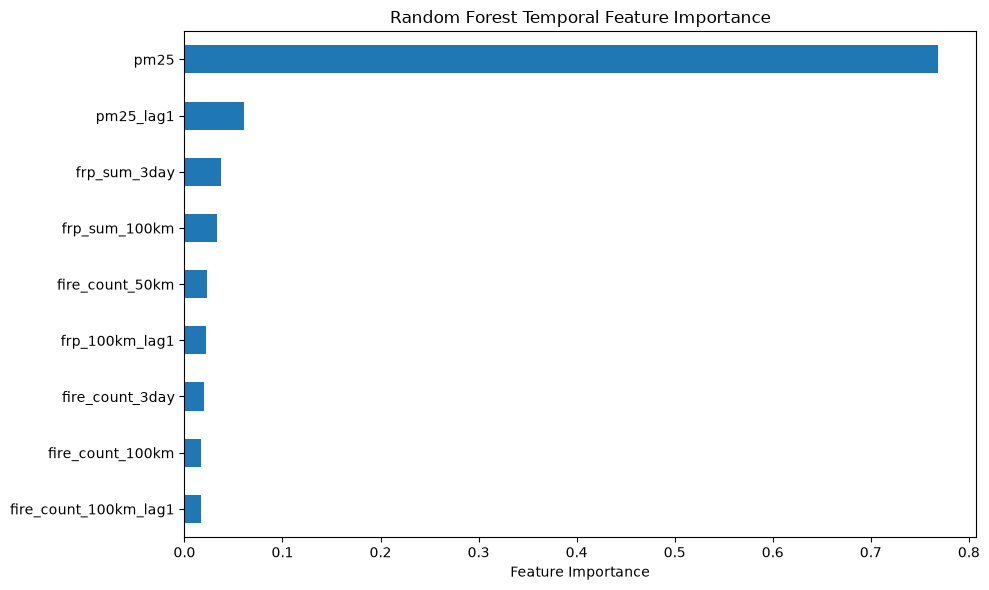

In [10]:

import matplotlib.pyplot as plt

importance = pd.Series(
    rf_temporal.feature_importances_,
    index=temporal_features
).sort_values()

plt.figure(figsize=(10, 6))

importance.plot.barh()

plt.title("Random Forest Temporal Feature Importance")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()
